<a href="https://colab.research.google.com/github/i5head/Applied-Deep-Learning/blob/main/Turorial3_fashionmnist_applied_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.model_selection import train_test_split
import seaborn as sns
from tensorflow.keras.utils import to_categorical


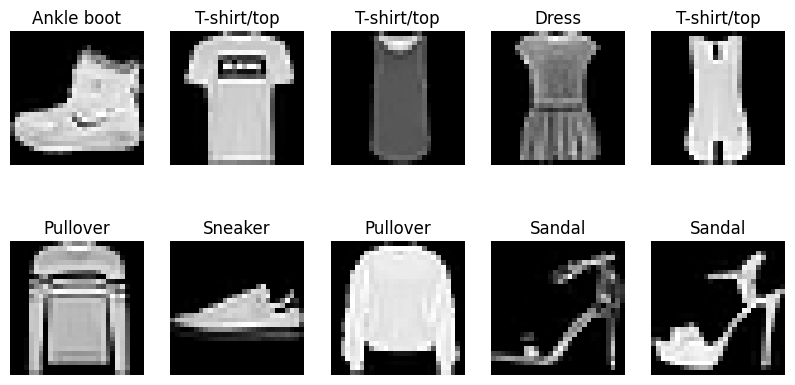

In [ ]:
# 1. Load the Fashion-MNIST dataset
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Display a few sample images
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap="grey")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")
plt.show()

In [ ]:
# 2. Normalize the data to [0, 1]
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add a channel dimension (since CNN expects 4D input)
x_train_full = np.expand_dims(x_train_full, -1)
x_test = np.expand_dims(x_test, -1)

print(x_train_full.shape)


(60000, 28, 28, 1)


In [ ]:
# 3. Split into training (50%), validation (25%), test (25%)

x_train, x_val, y_train, y_val = train_test_split(x_train_full, y_train_full, test_size=0.5, random_state=42)
x_val, x_train, y_val, y_train = train_test_split(x_train, y_train, test_size=0.5, random_state=42)

# double splitt of the data set into 3 different kind of sets

print(x_train.shape)
print(x_val.shape)
print(x_test.shape)

(15000, 28, 28, 1)
(15000, 28, 28, 1)
(10000, 28, 28, 1)


In [ ]:
# 3.1 Convert the labels to a one-hot encoding
print(y_train.shape)
print(x_train.shape)


(15000,)
(15000, 28, 28, 1)


In [ ]:
# 4. Define a CNN classifier
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dense(10, activation='softmax'),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


In [ ]:
# 4.1 Good practise is to show the layers of the model
print(model.summary())

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 13, 13, 10)     │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 1690)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       216,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,388 (853.08 KB)

 Trainable params: 218,388 (853.08 KB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
print("x shape:", x_train.shape)
print("y shape:", y_train.shape)
print("Model output:", model.output_shape)

x shape: (15000, 28, 28, 1)
y shape: (15000,)
Model output: (None, 10)


In [ ]:
# 5. Train the model
history = model.fit(x_train, y_train, epochs=10, validation_data=(x_val, y_val))

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.6621 - loss: 0.9259 - val_accuracy: 0.7773 - val_loss: 0.5979
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.8073 - loss: 0.5062 - val_accuracy: 0.8128 - val_loss: 0.5102
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.8354 - loss: 0.4450 - val_accuracy: 0.8355 - val_loss: 0.4496
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - accuracy: 0.8519 - loss: 0.4045 - val_accuracy: 0.8482 - val_loss: 0.4138
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.8637 - loss: 0.3748 - val_accuracy: 0.8479 - val_loss: 0.4077
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.8679 - loss: 0.3521 - val_accuracy: 0.8551 - val_loss: 0.3999
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.8791 - loss: 0.3284 - val_accuracy: 0.8555 - val_loss: 0.3894
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.8831 - loss: 0.3122 - 

In [ ]:
# 5.1 Evaluate the model on the test data
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'\nTest accuracy: {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8697 - loss: 0.3593

Test accuracy: 0.869700014591217


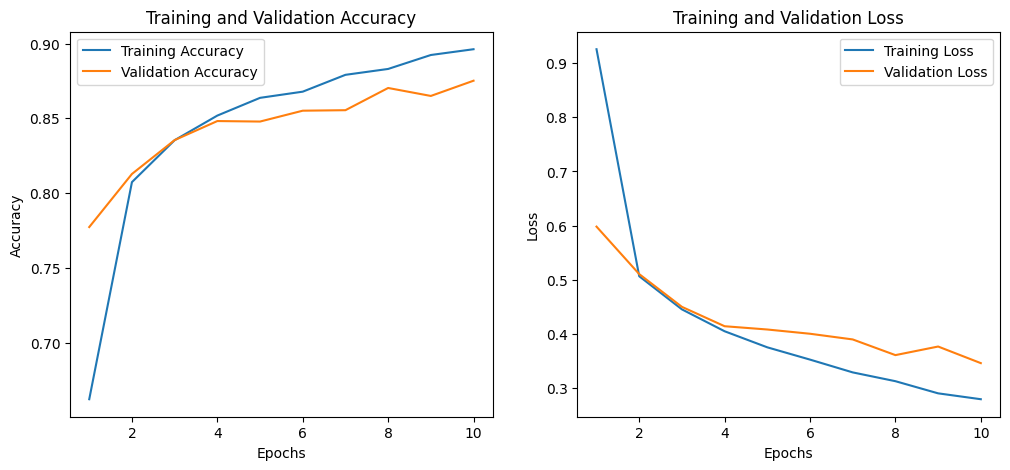

In [ ]:
# 6. Plot learning curves
# Plot training & validation accuracy and loss, COPY THIS
def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Plot training & validation accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Training Accuracy')
    plt.plot(epochs, val_acc, label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot training & validation loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Training Loss')
    plt.plot(epochs, val_loss, label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()


plot_training_history(history)

In [ ]:
# 7. ROC Curves (one-vs-all)
# Generate ROC curves for each digit (one-vs-rest)
def plot_roc_curves(y_true, y_pred):
    y_true_bin = label_binarize(y_true, classes=np.arange(10))

    plt.figure(figsize=(12, 8))
    colors = plt.get_cmap('tab10')

    for i in range(10):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred[:, i]) # false positive rate and true positive rate - give true label and the model prediciton

        # Compute the standard ROC AUC before any transformation
        roc_auc = auc(fpr, tpr)

        # Exclude zero FPR values to avoid division by zero
        mask = fpr > 0

        plt.plot(
            tpr[mask],
            1.0 / fpr[mask],
            color=colors(i),
            lw=2,
            label=f'Digit {i} (AUC = {roc_auc:.5f})'
        )

    plt.yscale("log")
    plt.xlim([0.7, 1.0])
    plt.ylabel('1 / False Positive Rate')
    plt.xlabel('True Positive Rate')
    plt.title('ROC Curves for Each Digit')
    plt.legend(loc='lower left')
    plt.show()

plot_roc_curves(y_test, model.predict(x_test))


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


NameError: name 'label_binarize' is not defined

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


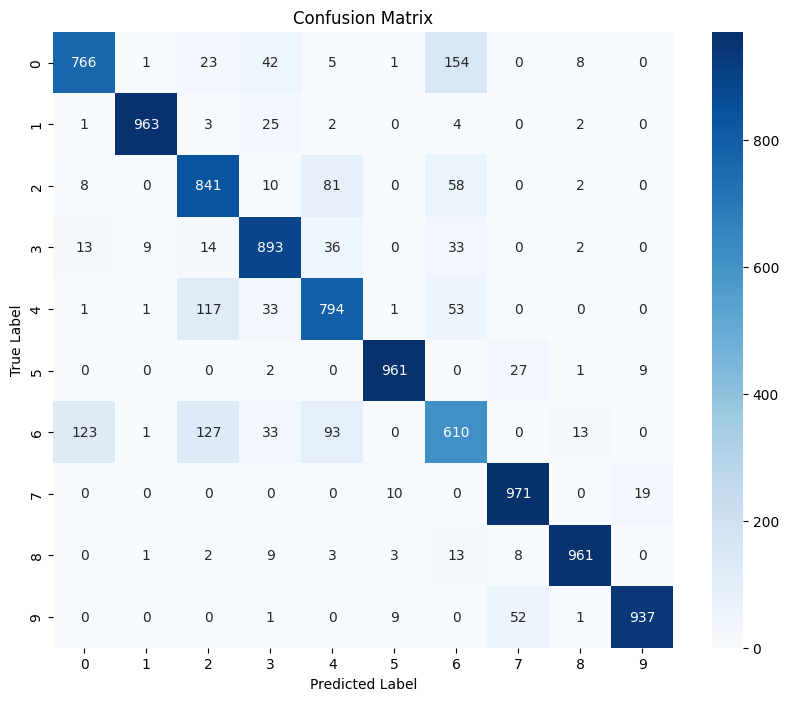

In [ ]:
# 8. Confusion Matrix
def plot_confusion_matrix(y_true, y_pred):
    y_pred_classes = np.argmax(y_pred, axis=1)
    cm = confusion_matrix(y_true, y_pred_classes)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.arange(10), yticklabels=np.arange(10))
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_confusion_matrix(y_test, model.predict(x_test))